# Step 0 - Surrogate model gate

Before any optimization: can the process features predict **Kappa** and **Viscosity**?

- Fit Linear + RandomForest per target, report **test R^2** and RF feature importance.
- **Gate rule:** if RF R^2 is low (< ~0.3), the model is too weak to trust - do NOT run `01_optimize`.
- Read-only. Uses `data/batch_master.csv` via `build_master.load_outputs()`. No PI.

In [1]:
import matplotlib.pyplot as plt
import surrogate

df = surrogate.load_master()
summary, results = surrogate.run_gate(df)
print(f"batches (quality_flag == ok): {len(df)}")
summary

batches (quality_flag == ok): 1463


,target,n,r2_linear,r2_rf,pass,note
0,press1_kappa,450,0.007,-0.194,False,
1,press1_viscosity,447,0.200,0.179,False,


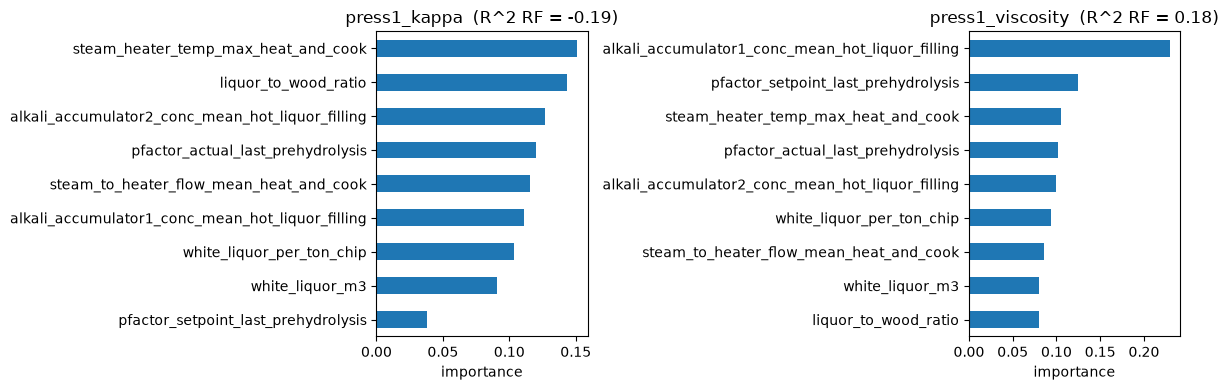

In [2]:
# Feature importance (RandomForest) per target.
ok = [t for t, r in results.items() if "importance" in r]
fig, axes = plt.subplots(1, len(ok), figsize=(6 * len(ok), 4))
axes = [axes] if len(ok) == 1 else axes
for ax, t in zip(axes, ok):
    results[t]["importance"].sort_values().plot.barh(ax=ax)
    ax.set_title(f"{t}  (R^2 RF = {results[t]['r2_rf']:.2f})")
    ax.set_xlabel("importance")
fig.tight_layout()
plt.show()

## Verdict

- **If `pass == True` for the targets you care about** -> go to `01_optimize.ipynb`.
- **If R^2 is low** -> the current X cannot explain quality. Do not optimize yet.
  Possible causes: weak/absent causal link, missing confounder control (time trend,
  production rate, lag), or features that are effects not causes. Fix the data first.

Record the R^2 numbers and the date in `update.md`.